# Unrolling Tutorial

This notebook demonstrates how to derive flattened x/y coordinates from SMURF cell-level outputs using mouse brain and mouse small intestine examples.

### Dataset Information

Access the datasets here:
- [Visium HD CytAssist Gene Expression Libraries of Mouse Brain (FFPE)](https://www.10xgenomics.com/datasets/visium-hd-cytassist-gene-expression-libraries-of-mouse-brain-he)
- [Visium HD Spatial Gene Expression Library, Mouse Small Intestine (FFPE)](https://www.10xgenomics.com/datasets/visium-hd-cytassist-gene-expression-libraries-of-mouse-intestine)

The unrolling workflow has three conceptual steps:

1. identify candidate x-axis cells using prior clustering results together with spatial location and biological interpretation;
2. clean the selected cells and optionally preserve broken fragments that belong to the x-axis but should be excluded from fitting;
3. fit the x-axis and then compute y coordinates using either direct distance (`su.y_axis`) or graph-based relative distance (`su.y_axis_circle`).

Use `su.y_axis` when Euclidean distance to the axis is biologically meaningful. Use `su.y_axis_circle` for rolled or circular tissues in which cells should be connected stepwise to the axis.

Main functions for unwrolling contains:

1. [su.select_cells()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.select_cells()): to select the cells from the boundary cluster for the x-axis. [su.select_cells()]
2. [su.clean_select()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.clean_select()): to clean the selected.
3. [su.x_axis()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.x_axis()-and-su.x_axis_pre()) and [su.x_axis_pre()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.x_axis()-and-su.x_axis_pre()): to build the x-axis.
5. [su.select_rest_cells()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.select_rest_cells()): to find all remaining cells for the y-axis.
6. [su.y_axis()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.y_axis()) and [su.y_axis_circle()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.y_axis_circle()) to get the final y-axis results.
   
In the meantime, we can use `su.plot_selected()` to view our data and `su.plot_final_result()` to take a look at the final results.

For how to use SMURF to achieve your desired results, please refer to the examples. Thank you.

In [1]:
import scanpy as sc
import numpy as np
import smurf as su
import pandas as pd
import matplotlib.pyplot as plt

> **Note on software versions**
>
> This tutorial was developed and tested with the exact package versions listed below.  
> Using these versions should reproduce the results exactly.  
> Newer releases may introduce subtle differences.  
> If you encounter any issues, please open an issue on our [GitHub repository](https://github.com/The-Mitra-Lab/SMURF/issues) and we’ll respond as soon as possible. Thanks!

| Package        | Version        |
|----------------|----------------|
| numpy          | 1.26.4         |
| pandas         | 1.5.3          |
| tqdm           | 4.66.2         |
| scanpy         | 1.10.0         |
| scipy          | 1.12.0         |
| matplotlib     | 3.8.3          |
| numba          | 0.59.0         |
| scikit-learn   | 1.4.1.post1    |
| Pillow         | 10.2.0         |
| anndata        | 0.10.6         |
| h5py           | 3.10.0         |
| pyarrow        | 16.1.0         |
| igraph         | 0.11.5         |

Here are the python codes you can use to install the exact versions:
```python
import importlib.metadata as metadata
import subprocess
import sys

# Dictionary of desired package versions
desired_versions = {
    "numpy": "1.26.4",
    "pandas": "1.5.3",
    "tqdm": "4.66.2",
    "scanpy": "1.10.0",
    "scipy": "1.12.0",
    "matplotlib": "3.8.3",
    "numba": "0.59.0",
    "scikit-learn": "1.4.1.post1",
    "Pillow": "10.2.0",
    "anndata": "0.10.6",
    "h5py": "3.10.0",
    "pyarrow": "16.1.0",
    "igraph": "0.11.5",
}

for pkg, target_ver in desired_versions.items():
    try:
        installed_ver = metadata.version(pkg)
    except metadata.PackageNotFoundError:
        installed_ver = None

    if installed_ver != target_ver:
        print(f"{pkg} current version: {installed_ver or 'not installed'}, installing/upgrading to {target_ver}…")
        subprocess.run(
            [sys.executable, "-m", "pip", "install", f"{pkg}=={target_ver}"],
            check=True
        )
    else:
        print(f"{pkg} is already at version {target_ver}, no action needed.")
```


# Unrolling Mouse Brain Data

Let's first start with the mouse brain example.

To download the final result directly:
``` python
! wget https://github.com/The-Mitra-Lab/SMURF/releases/download/datasets/adata_sc_final_mousebrain.h5ad.gz
! gunzip adata_sc_final_mousebrain.h5ad.gz 
```

In [2]:
#! wget https://github.com/The-Mitra-Lab/SMURF/releases/download/datasets/adata_sc_final_mousebrain.h5ad.gz
#! gunzip adata_sc_final_mousebrain.h5ad.gz 

In [3]:
adata_sc_final_mousebrain = sc.read_h5ad('adata_sc_final_mousebrain.h5ad')
adata_sc_final_mousebrain

AnnData object with n_obs × n_vars = 56864 × 19059
    obs: 'cell_cluster', 'cos_simularity', 'cell_size', 'array_row', 'array_col', 'n_counts'
    var: 'gene_ids', 'feature_types'
    uns: 'spatial'
    obsm: 'spatial'

### su.select_cells()

`su.select_cells(adata, cluster, cluster_name='cell_cluster', spatial_name=['array_row', 'array_col'] , so=None)`

1. `adata`: Input your adata object.
2. `cluster`: Provide a list of clusters to be included.
3. `cluster_name`: Specify the name of the cluster in adata.obs.
4. `spatial_name`: A list of two strings specifying the names of the columns in `adata.obs` that contain the spatial coordinates. Defaults to `['array_row', 'array_col']` from SMURF soft segmentation.
5. `so`: If `spatial_name` are not in adata.obs, please input your `so` (spatial object) from the previous analysis.

The output of the selected data is a list containing two numpy arrays. The first array includes all the cell IDs selected, and the second array contains the coordinates of the corresponding cells.

In this example, we want to use cluster 13 to build the x-axis.

In [4]:
selected_mousebrain = su.select_cells(adata_sc_final_mousebrain, cluster = [13], cluster_name = 'cell_cluster')

Take a look at your data here.

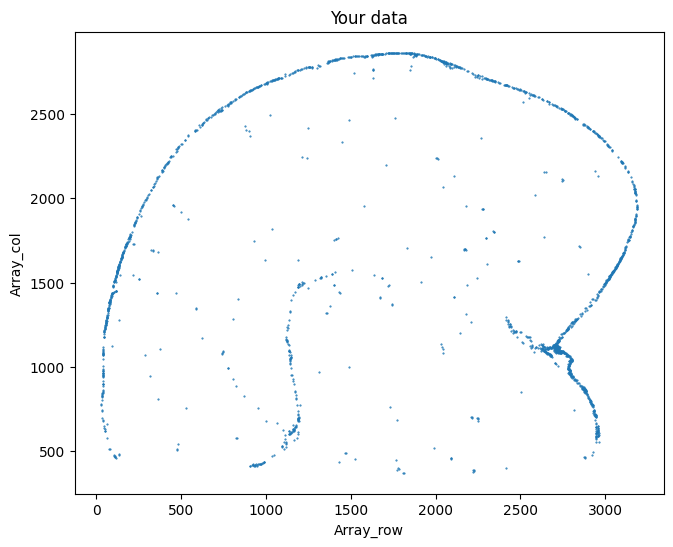

In [5]:
su.plot_selected(selected_mousebrain)

### su.clean_select() 

`su.clean_select(selected, left = None, right = None, up=None, down = None, outlier_cutoff=20, 
outlier_neighbors = 6, delete_xaxis = [np.array([]), np.zeros((0, 2))], return_deleted = False, save_area=[None, None, None, None], k_neighbors = 40, avg_iterations = 1)`

1. `selected`: Please input your selected data.
2. **Delete cells directly** `left`, `right`, `up`, `down`: We will delete all cells in these areas.
3. **Delete outliers** `outlier_cutoff`, `outlier_neighbors`, `k_neighbors`, `avg_iterations`: We will delete outliers that meet these criteria. Here, we first add points by averaging iterations (`avg_iterations`) with k neighbors (`k_neighbors`) to get denser cells. Then, we use k-nearest neighbors (k = `outlier_neighbors`) to find the distance between each cell and its neighbors, deleting the cell if the distance is larger than `outlier_cutoff`.
4. **Secure area** `save_area`: We will save all the cells in this area; these four values represent [`left`, `right`, `up`, `down`].
5. `delete_xaxis`, `return_deleted`=`False`: In some cases, there are data points on the x-axis, but they are disconnected due to certain reasons, making it impossible to determine the x-axis. We need to delete these points during analysis, but we need to save them as they originally belonged to the x-axis (please see the mouse intestine example for more details, but for now, you may ignore this part).


The output of this function includes the new selected data and to_delete (only if `return_deleted`=`True`).

**Since assigning a value to the output will modify `selected`, please confirm the parameters before making any actual changes.**

For this analysis, first run:

```python
su.clean_select(
    selected_mousebrain,
    delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
    down = None,
    up = 2000,
    right = 3160,
    left = 300,
    save_area = [0, 400, 600, 400],
    return_deleted = False,
    outlier_cutoff = 20,
    outlier_neighbors = 4,
    k_neighbors = 40,
    avg_iterations = 2
)

```
to preview the effect of the parameters. After confirming that the result looks appropriate, run:

```python
selected_mousebrain = su.clean_select(
    selected_mousebrain,
    delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
    down = None,
    up = 2000,
    right = 3160,
    left = 300,
    save_area = [0, 400, 600, 400],
    return_deleted = False,
    outlier_cutoff = 20,
    outlier_neighbors = 4,
    k_neighbors = 40,
    avg_iterations = 2
)
```
to update the selected cells.

You can repeat this process as needed to prepare the x-axis input.

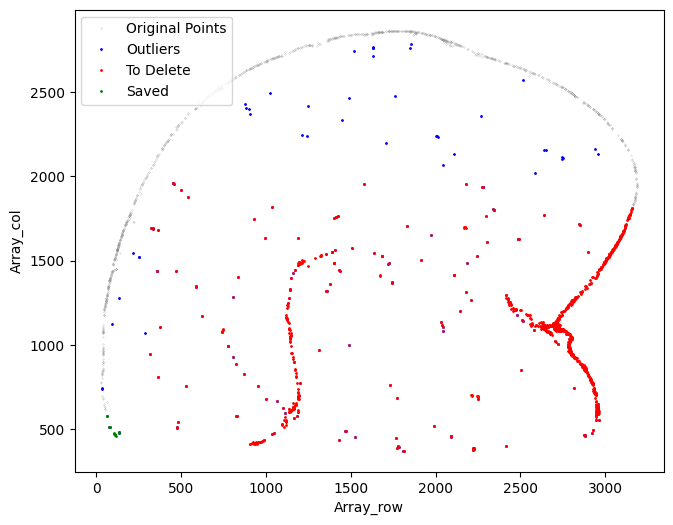

In [6]:
selected_mousebrain = su.clean_select(selected_mousebrain,
                                      delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))], 
                                      down = None, up = 2000, right = 3160, left = 300,
                                      save_area = [0,400,600,400],
                                      return_deleted = False, 
                                      outlier_cutoff = 20, 
                                      outlier_neighbors = 4, 
                                      k_neighbors = 40, 
                                      avg_iterations = 2)

### su.x_axis() and su.x_axis_pre()

We use [LocallyLinearEmbedding](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.LocallyLinearEmbedding.html) to fit the x-axis.

`su.x_axis(selected, adata, so=None, seed=42, n_neighbors=50, num_avg=35, unit=5, resolution=2, spatial_name=['array_row', 'array_col'])`

1. `selected`: selected cells from the previous step.
2. `adata` and `so`: the AnnData object and, if needed, the spatial object. If `'x'` and `'y'` are not already in `adata.obs`, provide `so`.
3. `seed`: random seed.
4. `n_neighbors`: number of neighbors for LocallyLinearEmbedding.
5. `num_avg` and `unit`: smoothing and spacing controls for the final x-axis.
6. `resolution`: spatial resolution of the sequencing technology. For Visium HD, this is 2 μm. Note that this `resolution` is different from the Leiden clustering resolution used in the segmentation tutorials.
7. `spatial_name`: names of the spatial-coordinate columns in `adata.obs`.

`su.x_axis_pre()` can be used to preview whether the selected cells are suitable for x-axis fitting before generating the final x-axis.

The output of this function is a units_number * 2 numpy array representing the x-axis.
   
`x_axis_pre(selected, seed=42, n_neighbors=50, spatial_name=['array_row', 'array_col'])`

This function is the same as `x_axis()`, but it only completes the first step. You should use this function first to confirm the values for `seed` and `n_neighbors`, then use `x_axis()` to obtain the final results.


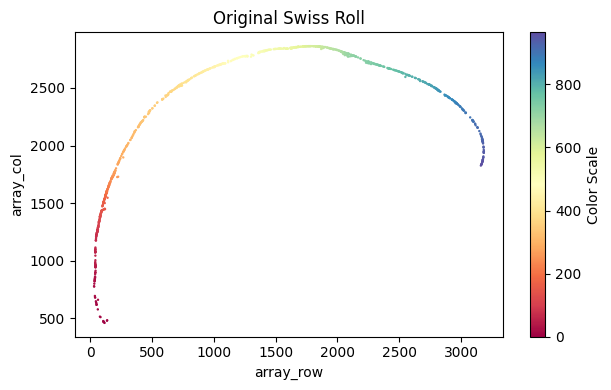

In [7]:
su.x_axis_pre(selected_mousebrain, seed=42, n_neighbors=50)

Make sure the unwrapping looks good here. Then, we will create the x-axis.

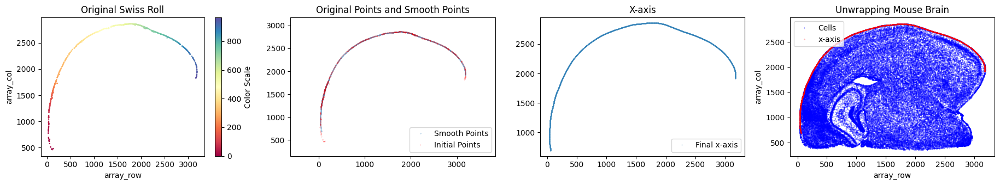

One unit length on the x-axis is 5.00 μm. The total x-axis length is 0.9959 cm.


In [8]:
x_axis_results_mousebrain = su.x_axis(selected_mousebrain, adata_sc_final_mousebrain)

### su.select_rest_cells()

`su.select_rest_cells(adata, selected=None, delete_xaxis=None, spatial_name=['array_row', 'array_col'], so=None)`

This function returns all remaining cells after excluding `selected` and `delete_xaxis`.

1. `adata`: input AnnData object.
2. `selected`: selected x-axis cells.
3. `delete_xaxis`: cells that biologically belong to the x-axis but were intentionally excluded from x-axis fitting.
4. `spatial_name`: names of the spatial-coordinate columns in `adata.obs`. The default is `['array_row', 'array_col']`.
5. `so`: if the spatial coordinates are not already stored in `adata.obs`, provide the spatial object from the segmentation workflow.

The output has the same format as `selected`.

In [9]:
cells_mousebrain = su.select_rest_cells(adata_sc_final_mousebrain, selected_mousebrain)

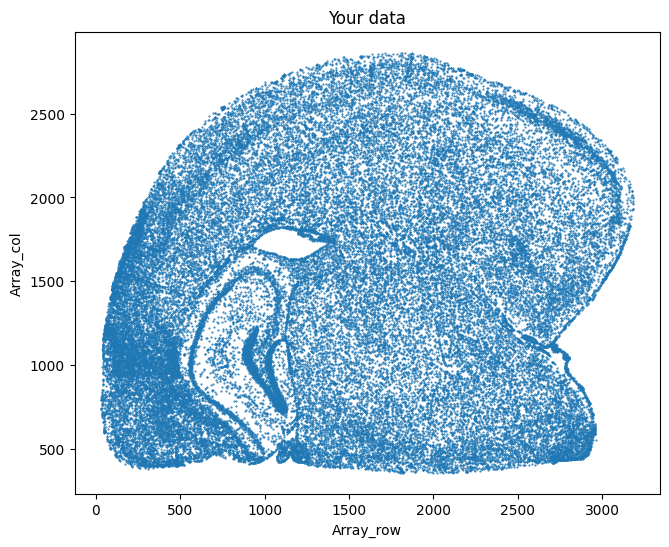

In [10]:
su.plot_selected(cells_mousebrain)

### su.y_axis()

`su.y_axis(x_axis, cells, selected=None, delete_xaxis=[[np.zeros((0, 1))], np.zeros((0, 2))], delete_residues=False, unit=5, resolution=2, center=None, spatial_name=['array_row', 'array_col'])`

We use this function to derive y coordinates based on straight-line distance to the x-axis.

1. `x_axis`: x-axis results from the previous step.
2. `cells`: cells used for y-axis unrolling.
3. `selected`: x-axis cells; their y values will be set to 0.
4. `delete_xaxis`: cells that belong to the x-axis but were intentionally excluded from fitting.
5. `delete_residues`: whether to remove residual cells assigned to the two ends of the x-axis when `delete_xaxis` is empty. The default is `False`.
6. `unit`: the x-axis unit in μm.
7. `resolution`: spatial resolution of the sequencing technology. For Visium HD, this is 2 μm. Note that this is not the Leiden clustering resolution used in the segmentation tutorial.
8. `center`: optional reference center used to control directionality.
9. `spatial_name`: names of the spatial-coordinate columns in `adata.obs`.

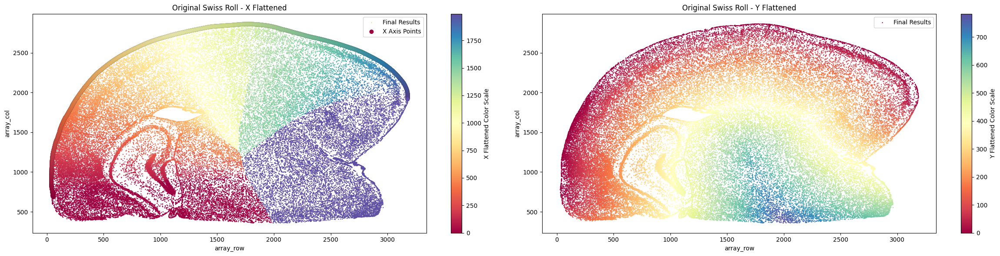

In [11]:
final_result_mousebrain = su.y_axis(x_axis_results_mousebrain, cells_mousebrain, selected_mousebrain)

Finally, filter for the part you want and take a look!

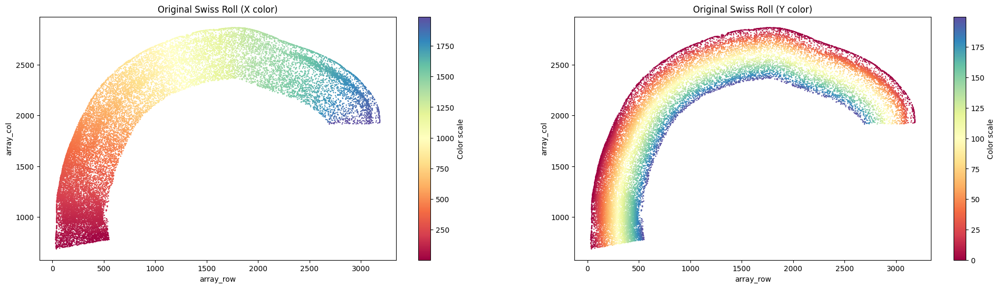

In [12]:
final_result_mousebrain = final_result_mousebrain[(final_result_mousebrain['x_flattened'] > 0) & 
                                                  (final_result_mousebrain['x_flattened'] < final_result_mousebrain['x_flattened'].max()) & 
                                                  (final_result_mousebrain['y_flattened'] < 200)]

su.plot_final_result(final_result_mousebrain)

As mentioned earlier, some datasets require a graph-based relative distance for the y-axis, where each cell must connect stepwise to another cell before reaching the x-axis. This is especially useful for rolled or circular tissue structures. We can also demonstrate the method on mouse brain data, although the small intestine example below is the primary use case.

### su.y_axis_circle()

`su.y_axis_circle(x_axis, cells, delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))], selected=None, n_neighbors_first=18, n_neighbors_rest=7, distance_cutoff=23, center=None, outside=True, max_iter=1000, unit=5, resolution=2, spatial_name=['array_row', 'array_col'])`

Here, we use a graph-based relative distance, where each cell must connect to neighboring cells stepwise before reaching the x-axis.

1. `x_axis`: x-axis results.
2. `cells`: cells used for y-axis unrolling.
3. `delete_xaxis`: cells that belong to the x-axis but were intentionally excluded from fitting.
4. `selected`: x-axis cells; their layer value will be set to 0.
5. `n_neighbors_first`: number of neighbors used when connecting cells to the x-axis initially.
6. `n_neighbors_rest`: number of neighbors used for subsequent graph expansion.
7. `distance_cutoff`: maximum local connection distance.
8. `center`: optional reference center.
9. `outside`: if `True`, y extends outward from the center; if `False`, inward.
10. `max_iter`: maximum number of expansion iterations.
11. `unit`: x-axis unit in μm.
12. `resolution`: spatial resolution of the sequencing technology. For Visium HD, this is 2 μm.
13. `spatial_name`: names of the spatial-coordinate columns in `adata.obs`.

The output of this function is a pandas array of the cells and their information. You can directly concatenate it to adata.obs if desired.

80it [00:45,  1.77it/s, Layer=79] 


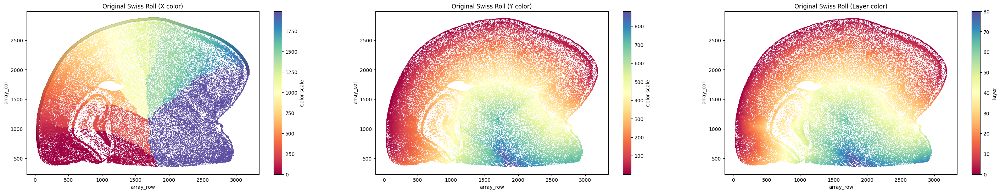

In [13]:
final_result_mousebrain_circle = su.y_axis_circle(x_axis_results_mousebrain, cells_mousebrain, 
                                                  selected = selected_mousebrain, 
                                                  n_neighbors_first = 16, n_neighbors_rest = 20, 
                                                  distance_cutoff = 100, center = None, 
                                                  outside = True, max_iter = 1000)

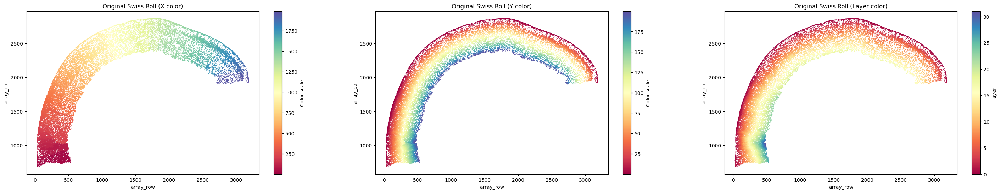

In [14]:
final_result_mousebrain_circle = final_result_mousebrain_circle[(final_result_mousebrain_circle['x_flattened'] > 0) & 
                                 (final_result_mousebrain_circle['x_flattened'] < final_result_mousebrain_circle['x_flattened'].max()) & 
                                 (final_result_mousebrain_circle['y_flattened'] < 200)]

su.plot_final_result(final_result_mousebrain_circle)

### Another version

In the previous example, we used one mouse-brain layer as the x-axis for unrolling. As an alternative, we can also use a cortical boundary-derived layer. Below is an example workflow.

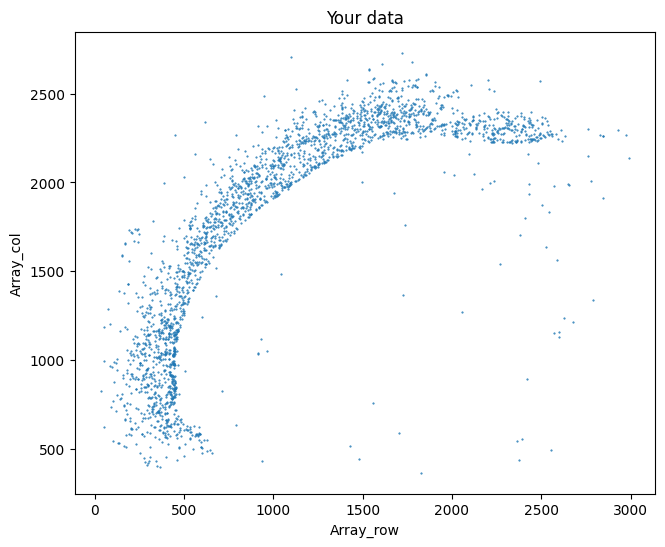

In [15]:
selected_mousebrain2 = su.select_cells(adata_sc_final_mousebrain, [5], cluster_name = 'cell_cluster')
su.plot_selected(selected_mousebrain2)

### su.select_boundary()

`su.select_boundary(selected, alpha=None, auto_alpha_quantile=80, dedup_tol=1e-7, ratio=None, show_plot=True)`

We use this function to extract the boundary of the selected cells.

1. `selected`: selected cells.
2. `alpha`: concave-hull (alpha-shape) tightness. Larger values usually produce a tighter boundary. If `None`, it is estimated automatically.
3. `auto_alpha_quantile`: quantile used when `alpha=None`.
4. `dedup_tol`: tolerance used to deduplicate nearly identical boundary points.
5. `ratio`: optional simplification / downsampling control, if used.
6. `show_plot`: whether to visualize the boundary.

The output contains the boundary cells of the selected region.

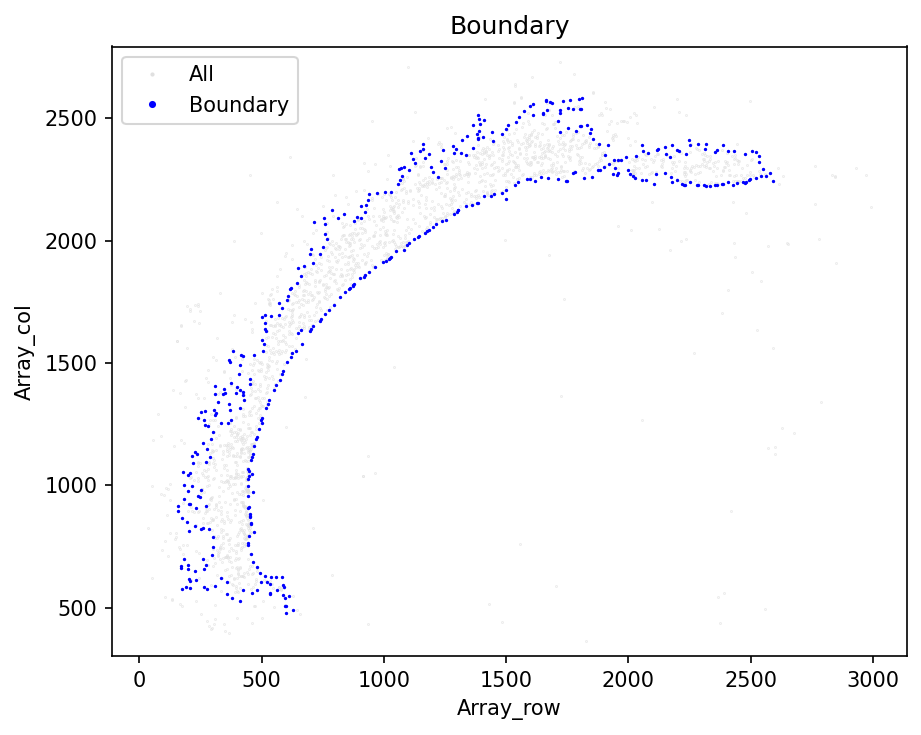

In [16]:
selected_mousebrain2 = su.select_boundary(selected_mousebrain2)

Next, we refine the specific layer to be unrolled. We apply `su.clean_select` multiple times to prepare a suitable set of cells for x-axis analysis.

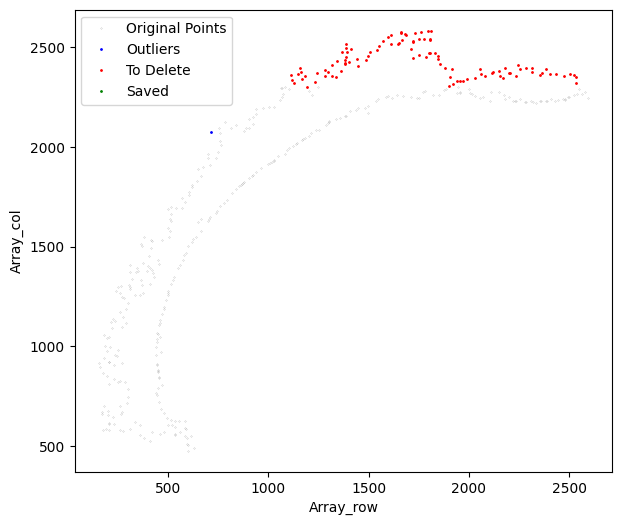

In [17]:
selected_mousebrain2 = su.clean_select(selected_mousebrain2, 
                                       delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
                                       down = 2300, up = 2600, left = 0, right = 3000, 
                                       return_deleted = False, 
                                       outlier_cutoff = 60, 
                                       outlier_neighbors = 5,
                                       k_neighbors = 40, 
                                       avg_iterations = 4)

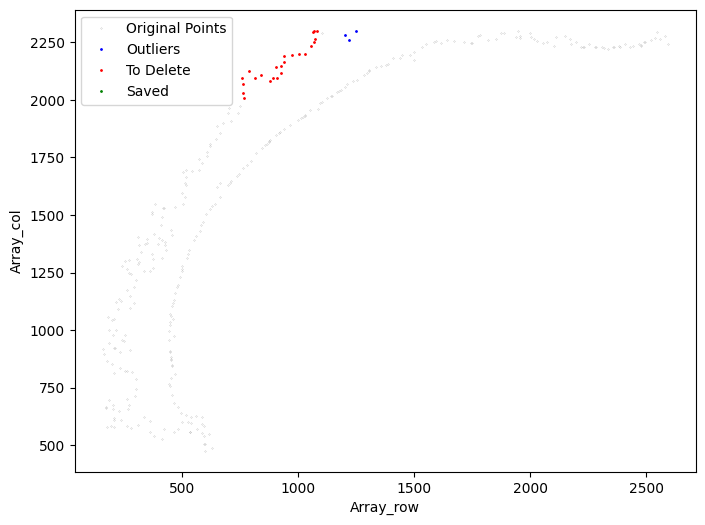

In [18]:
selected_mousebrain2 =  su.clean_select(selected_mousebrain2, 
                                        delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
                                        down = 2000, up = 2600, left = 0, right = 1100, 
                                        return_deleted = False, 
                                        outlier_cutoff = 60, 
                                        outlier_neighbors = 5, 
                                        k_neighbors = 40, 
                                        avg_iterations = 4)

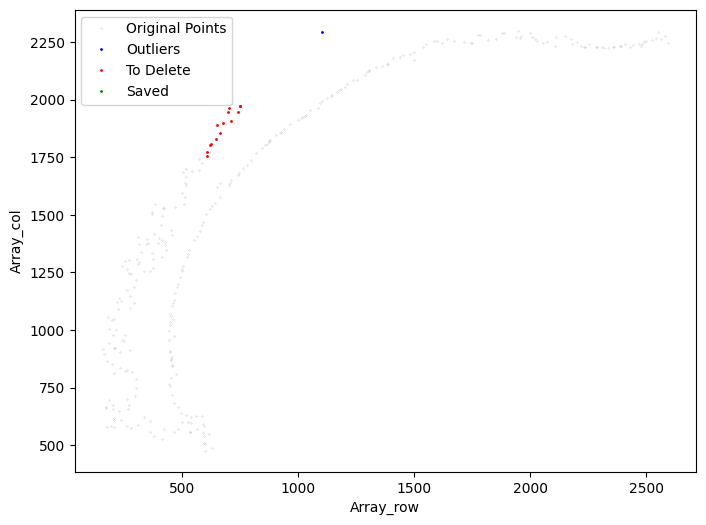

In [19]:
selected_mousebrain2 = su.clean_select(selected_mousebrain2, 
                                       delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
                                       down = 1750, up = 2600, left = 0, right = 800, 
                                       return_deleted = False, 
                                       outlier_cutoff = 60, 
                                       outlier_neighbors = 5, 
                                       k_neighbors = 40, 
                                       avg_iterations = 4)

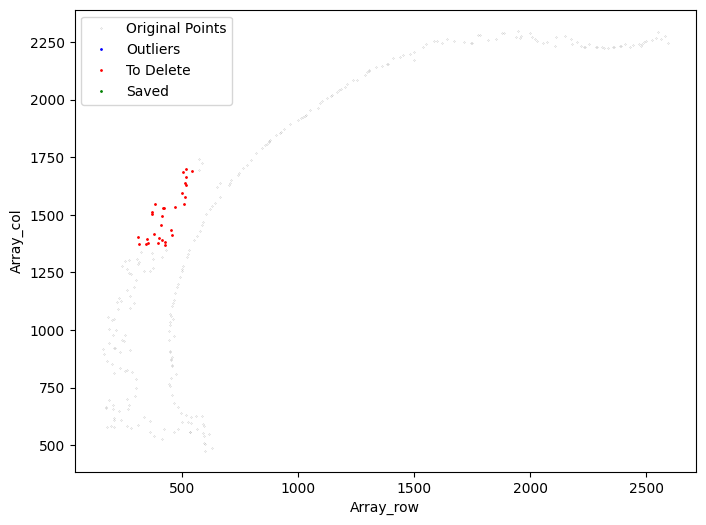

In [20]:
selected_mousebrain2 = su.clean_select(selected_mousebrain2,
                                       delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
                                       down = 1350, up = 2600, left = 0, right = 550, 
                                       return_deleted = False, 
                                       outlier_cutoff = 60, 
                                       outlier_neighbors = 5,
                                       k_neighbors = 40, 
                                       avg_iterations = 4)

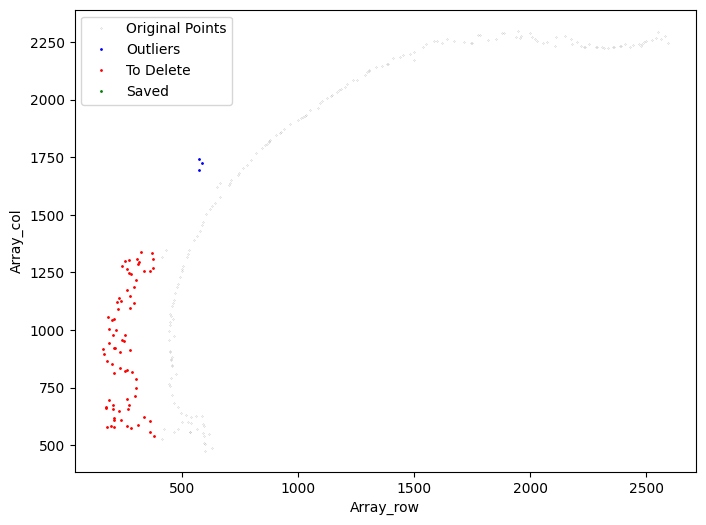

In [21]:
selected_mousebrain2 = su.clean_select(selected_mousebrain2, 
                                       delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
                                       right = 400, 
                                       return_deleted = False, 
                                       outlier_cutoff = 60, 
                                       outlier_neighbors = 5, 
                                       k_neighbors = 40, 
                                       avg_iterations = 4)

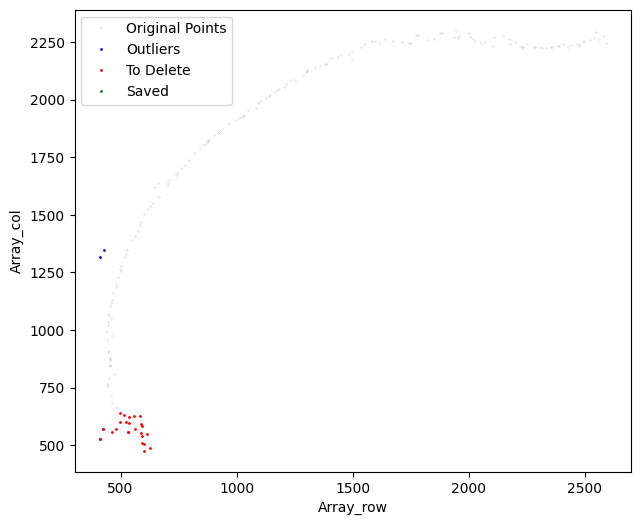

In [22]:
selected_mousebrain2 = su.clean_select(selected_mousebrain2, 
                                       delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
                                       down = 0, up = 650, 
                                       return_deleted = False, 
                                       outlier_cutoff = 60, 
                                       outlier_neighbors = 5, 
                                       k_neighbors = 40, 
                                       avg_iterations = 4)

Next, we begin constructing the x-axis.

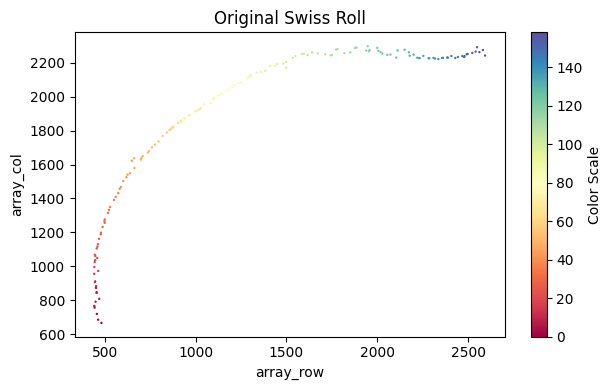

In [23]:
su.x_axis_pre(selected_mousebrain2, seed=42)

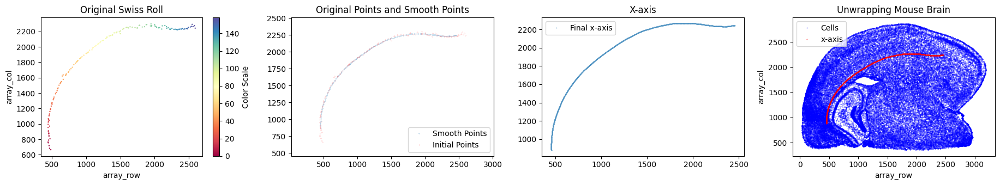

One unit length on the x-axis is 5.00 μm. The total x-axis length is 0.5542 cm.


In [24]:
x_axis_results_mousebrain2 = su.x_axis(selected_mousebrain2, adata_sc_final_mousebrain, num_avg=20)

In [25]:
cells_mousebrain2 = su.select_rest_cells(adata_sc_final_mousebrain, selected_mousebrain2)

Next, we define the Y-axis and use the `center` as a pivot to control its orientation. The direction from each cell to the x-axis must match the direction from the cell to the `center`. Please select the appropriate `center` to meet this requirement.

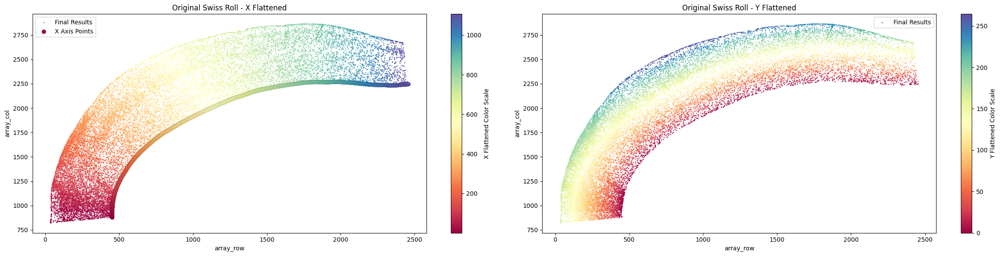

In [26]:
final_result_mousebrain2 = su.y_axis(x_axis_results_mousebrain2, cells_mousebrain2, selected_mousebrain2, 
                                    center = np.array([3000,200]), delete_residues = True )

To better understand the role of `center`, we remove it to observe the differences.

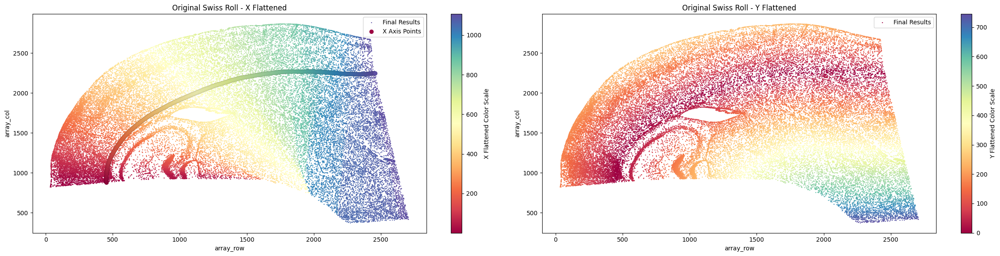

In [27]:
final_result_mousebrain2 = su.y_axis(x_axis_results_mousebrain2, cells_mousebrain2, 
                                     selected_mousebrain2, delete_residues = True)

# Unrolling Mouse Small Intestine Data

Let's first start with the Mouse Small Intestine example.

Like previously, we will introduce the steps in this example:

1. Use [su.select_cells()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.select_cells()) to select the cells from the boundary cluster for the x-axis.
2. Use [su.clean_select()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.clean_select()) to clean the selected data.
3. Use [su.x_axis()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.x_axis()-and-su.x_axis_pre()) to build the x-axis.
4. Use [su.select_rest_cells()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.select_rest_cells()) to find all remaining cells for the y-axis.
5. Use [su.y_axis_circle()](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/unroll_example.html#su.y_axis_circle()) to get the final results. Note that this step is different from previous example as we do not use direct distance for unrolling y axis.

In the meantime, we can use `su.plot_selected()` to view our data and `su.plot_final_result()` to take a look at the final results.

To download the final result directly:
``` python
! wget https://github.com/The-Mitra-Lab/SMURF/releases/download/datasets/adata_sc_final_smallintestine.h5ad.gz
! gunzip adata_sc_final_smallintestine.h5ad.gz 
```

In [28]:
#! wget https://github.com/The-Mitra-Lab/SMURF/releases/download/datasets/adata_sc_final_smallintestine.h5ad.gz
#! gunzip adata_sc_final_smallintestine.h5ad.gz 

In [29]:
adata_sc_final_smallintestine =  sc.read_h5ad('adata_sc_final_smallintestine.h5ad')
adata_sc_final_smallintestine

AnnData object with n_obs × n_vars = 404392 × 19059
    obs: 'cell_cluster', 'cos_simularity', 'cell_size', 'array_row', 'array_col', 'n_counts'
    var: 'gene_ids', 'feature_types'
    uns: 'spatial'
    obsm: 'spatial'

## Small intestine: selecting x-axis cells

Here, we select clusters 20, 23, and 24 as candidate x-axis cells for the small intestine example. These clusters were identified based on their spatial positions together with biological interpretation of the tissue structure.

In [30]:
selected_smallintestine = su.select_cells(adata_sc_final_smallintestine, [20, 23, 24], cluster_name = 'cell_cluster')

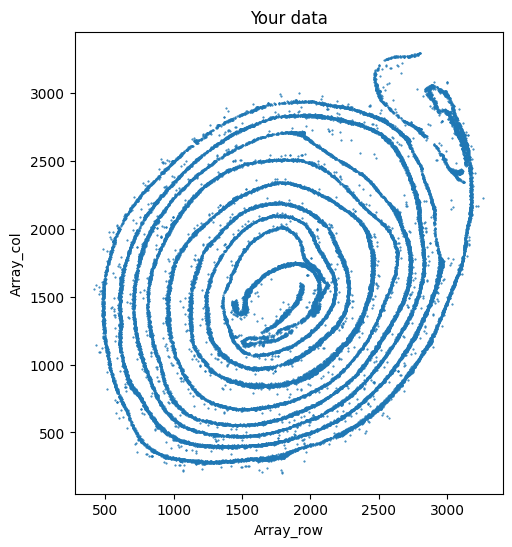

In [31]:
su.plot_selected(selected_smallintestine)

## Small intestine: cleaning selected cells

For this small intestine example, first run:

```python
su.clean_select(
    selected_smallintestine,
    delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))],
    save_area=[0, 400, 600, 400],
    return_deleted = False,
    outlier_cutoff=15,
    outlier_neighbors=4,
    k_neighbors = 40,
    avg_iterations = 2
)
```
to preview the effect of the parameters. Then apply the same function to update the selected cells.

In this example, we use a permissive first round `(outlier_cutoff=15)` and then tighten the cleanup in later rounds `(outlier_cutoff=14)` as needed. It is normal to repeat this process several times before x-axis fitting.

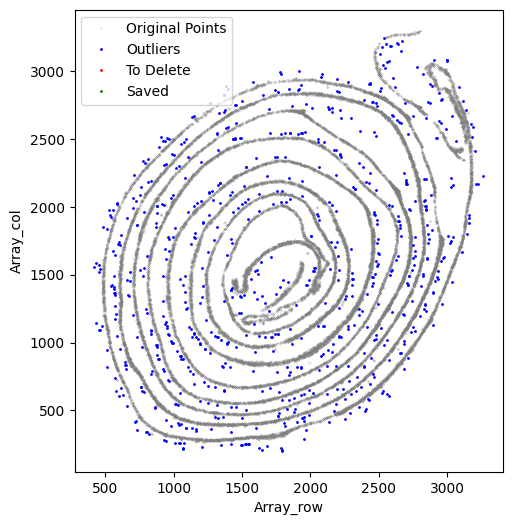

In [32]:
selected_smallintestine = su.clean_select(selected_smallintestine, 
                                          delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))], 
                                          save_area = [0,400,600,400], 
                                          return_deleted = False, 
                                          outlier_cutoff = 15, 
                                          outlier_neighbors =4, 
                                          k_neighbors = 40, 
                                          avg_iterations = 2)

It is normal to perform this process several times.

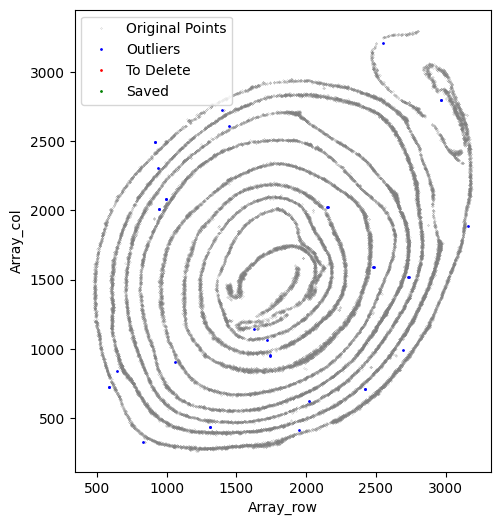

In [33]:
selected_smallintestine = su.clean_select(selected_smallintestine, 
                                          delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))], 
                                          save_area = [0,400,600,400], 
                                          return_deleted = False, 
                                          outlier_cutoff = 15, 
                                          outlier_neighbors =4, 
                                          k_neighbors = 40, 
                                          avg_iterations = 2)

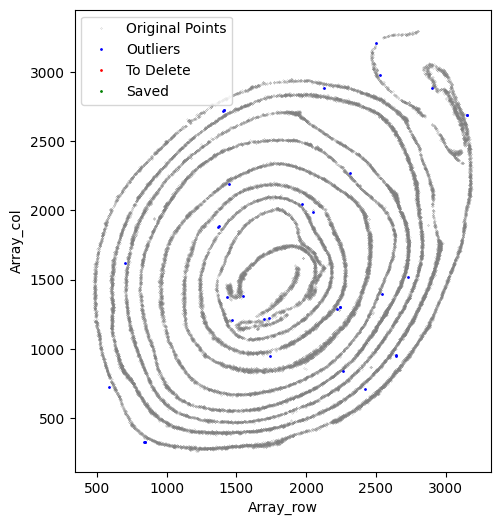

In [34]:
selected_smallintestine = su.clean_select(selected_smallintestine, 
                                          delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))], 
                                          save_area = [0,400,600,400], 
                                          return_deleted = False, 
                                          outlier_cutoff = 14, 
                                          outlier_neighbors =4, 
                                          k_neighbors = 40, 
                                          avg_iterations = 2)

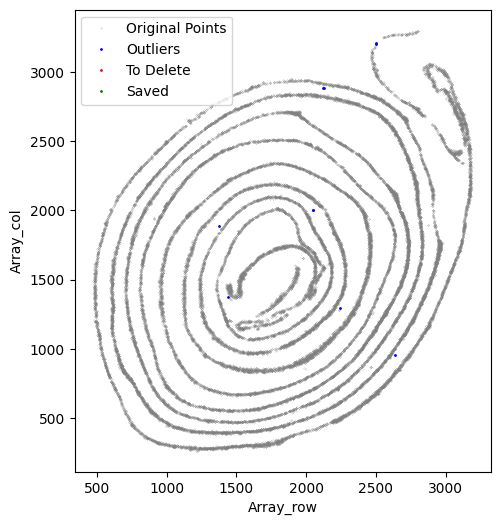

In [35]:
selected_smallintestine = su.clean_select(selected_smallintestine, 
                                          delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))], 
                                          save_area = [0,400,600,400], 
                                          return_deleted = False, 
                                          outlier_cutoff = 14, 
                                          outlier_neighbors =4, 
                                          k_neighbors = 40, 
                                          avg_iterations = 2)

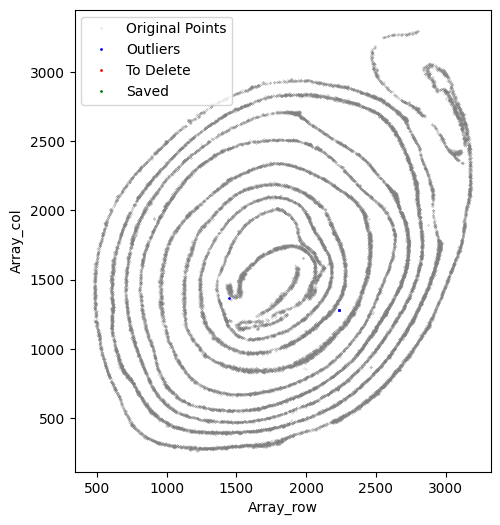

In [36]:
selected_smallintestine = su.clean_select(selected_smallintestine, 
                                          delete_xaxis = [[np.zeros((0, 1))], np.zeros((0, 2))], 
                                          save_area = [0,400,600,400], 
                                          return_deleted = False, 
                                          outlier_cutoff = 14, 
                                          outlier_neighbors = 4, 
                                          k_neighbors = 40, 
                                          avg_iterations = 2)

## Facing issues with broken tissues.

At this stage, we verify that the selected cells truly belong to the x-axis by running an x-axis preview analysis. In this example, the beginning and end regions do not fit well because of tissue overlap and local damage. We therefore remove these regions manually. Because these deleted parts still biologically belong to the x-axis but fall outside the analyzable range, we preserve them in `to_delete` and exclude them from subsequent y-axis analysis.

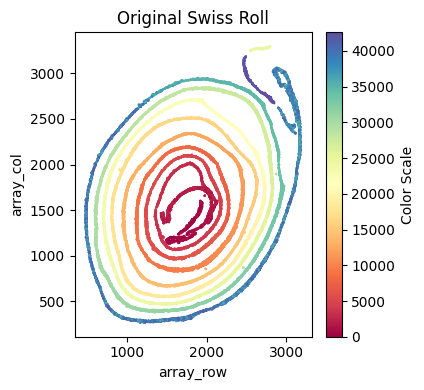

In [37]:
su.x_axis_pre(selected_smallintestine, seed=42, n_neighbors = 20)

Start preserving the deleted data. Remember, **do not assign values** to the data until you have confirmed the function parameters.

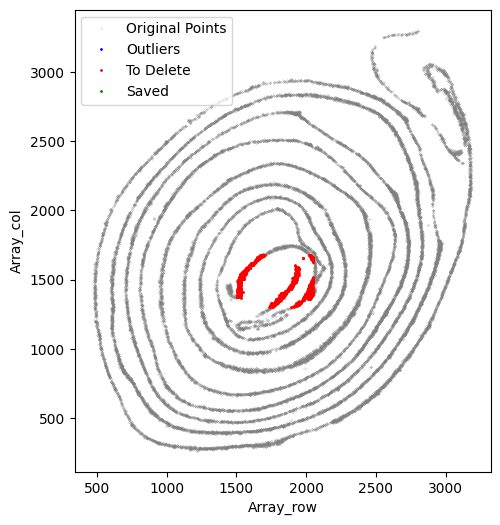

In [38]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1680, down = 1300, left = 1500, right = 2050, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     return_deleted = True)

**After obtaining the first `to_delete`, include it in subsequent function calls. Repeat this process as many times as needed.**

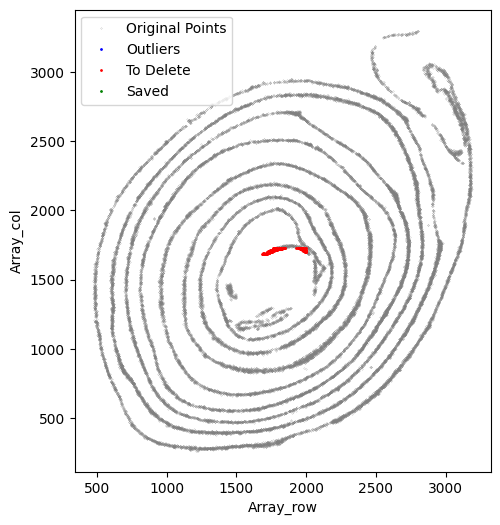

In [39]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1730, down = 1300, left = 1500, right = 2000, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

Repeat this cleanup process as many times as needed.

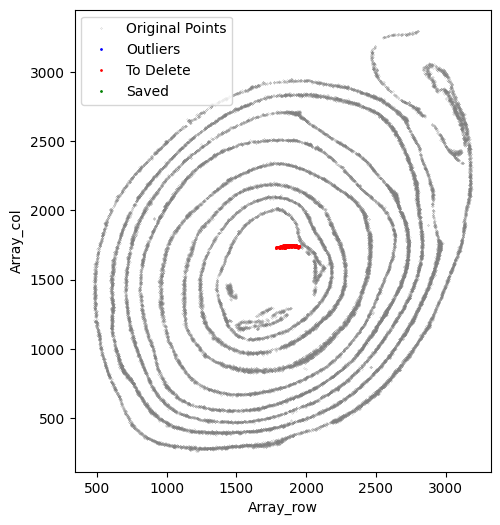

In [40]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1780, down = 1300, left = 1600, right = 1950, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

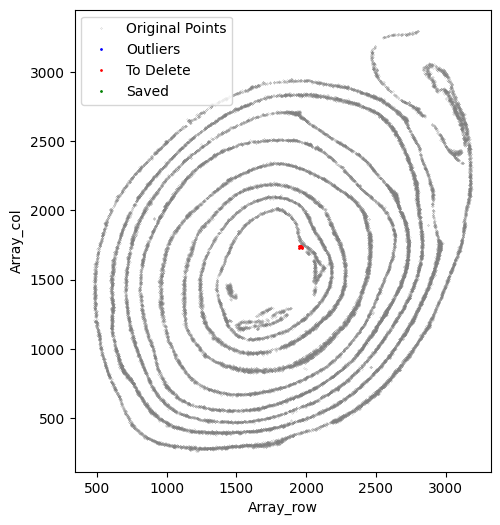

In [41]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1750, down = 1300, left = 1600, right = 1970, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

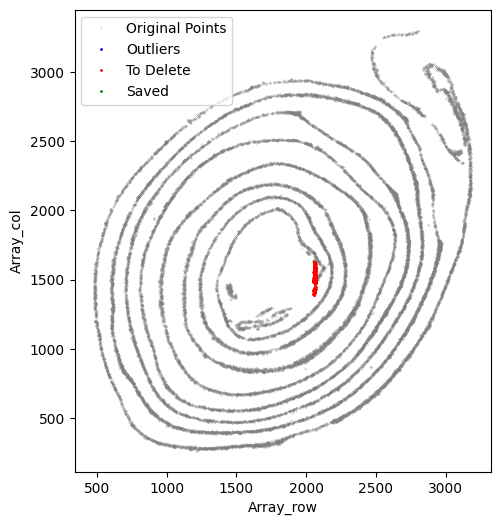

In [42]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1630, down = 1340, left = 1610, right = 2070, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

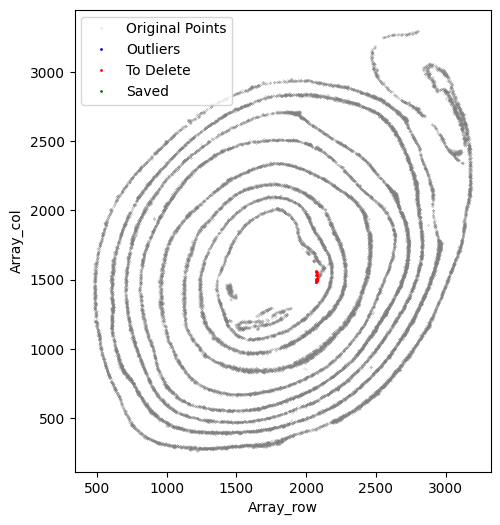

In [43]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1620, down = 1340, left = 1610, right = 2080, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

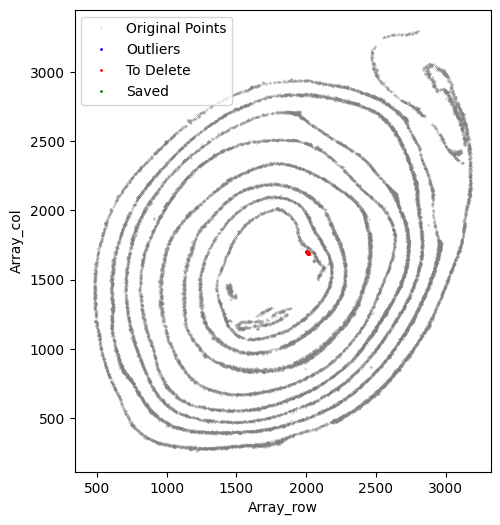

In [44]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1720, down = 1340, left = 1610, right = 2019, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

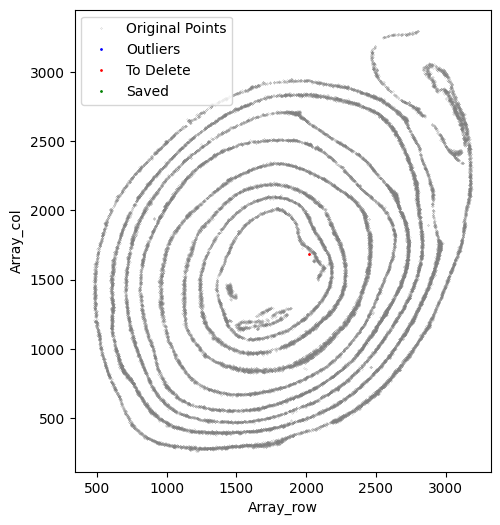

In [45]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1710, down = 1340, left = 1610, right = 2020, 
                                                    outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

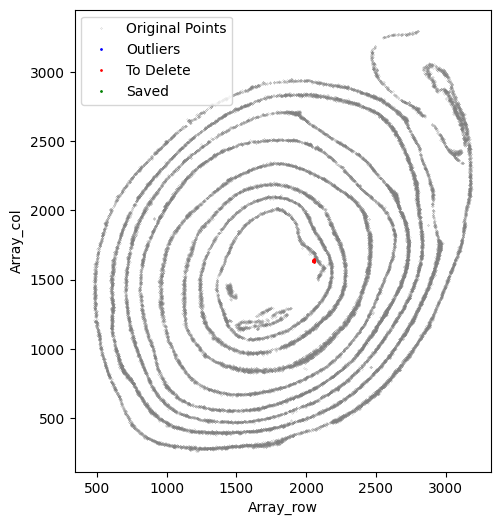

In [46]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1650, down = 1340, left = 1610, right = 2060, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

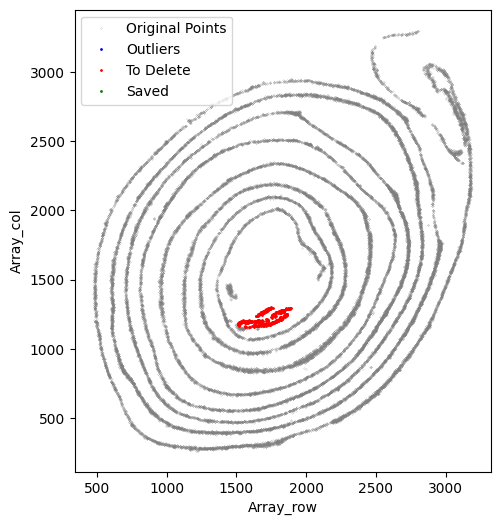

In [47]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1780, down = 1160, left = 1510, right = 1890, 
                                                     outlier_cutoff = 50, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

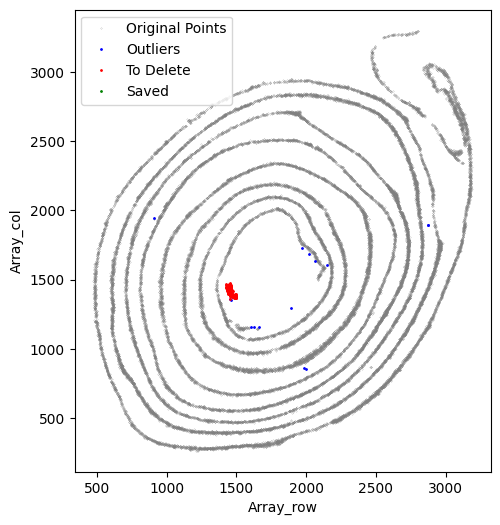

In [48]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1580, down = 1360, left = 1410, right = 1890, 
                                                     outlier_cutoff = 15, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

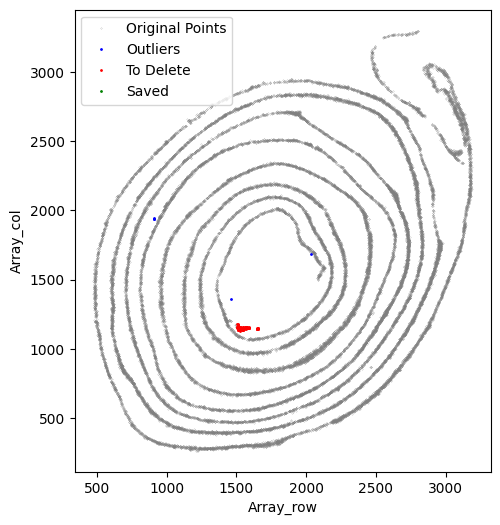

In [49]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1580, down = 1110, left = 1500, right = 1750, 
                                                     outlier_cutoff = 15, 
                                                     outlier_neighbors = 5, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True)

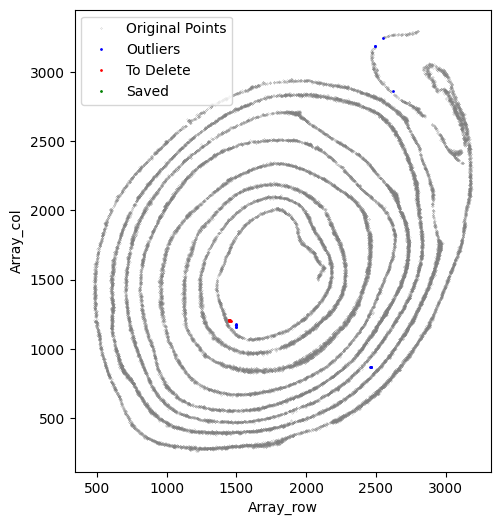

In [50]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     up = 1580, down = 1200, left = 1440, right = 1490, 
                                                     outlier_cutoff = 18, 
                                                     outlier_neighbors = 10, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True,
                                                     k_neighbors = 40, 
                                                     avg_iterations = 1)

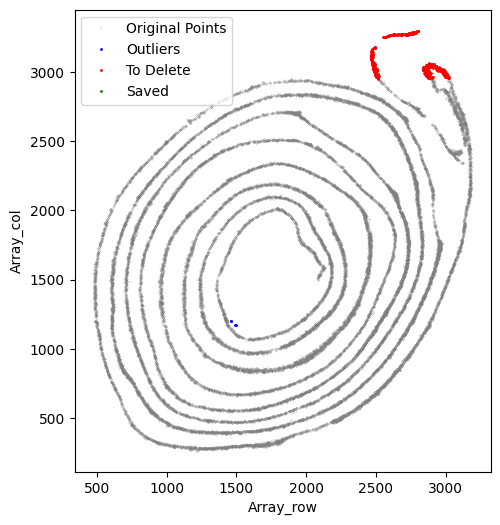

In [51]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     down = 2950,
                                                     outlier_cutoff = 18, 
                                                     outlier_neighbors = 10, 
                                                     delete_xaxis = to_delete, 
                                                     return_deleted = True,
                                                     k_neighbors = 40, 
                                                     avg_iterations = 1)

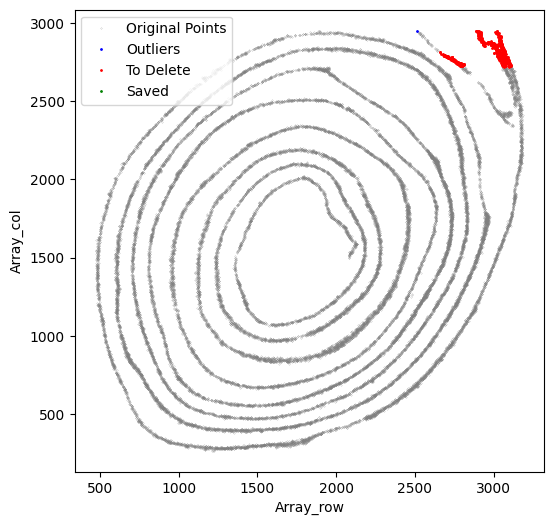

In [52]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     down = 2720, left = 2660, 
                                                     outlier_cutoff = 18, 
                                                     outlier_neighbors = 10, 
                                                     return_deleted = True,
                                                     delete_xaxis = to_delete, 
                                                     k_neighbors = 40, 
                                                     avg_iterations = 1)

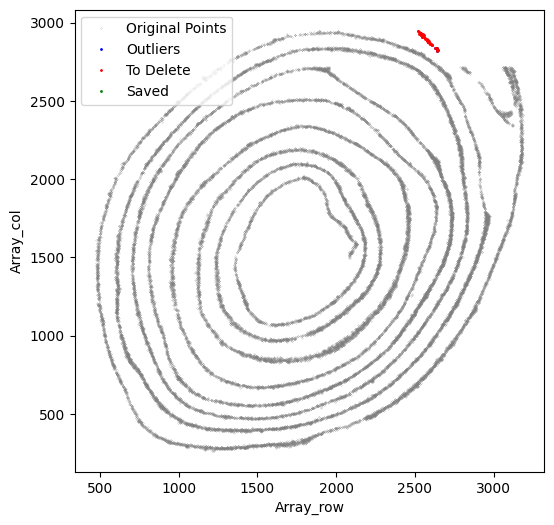

In [53]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     down = 2820, left = 2500, 
                                                     outlier_cutoff = 18,
                                                     outlier_neighbors = 10, 
                                                     return_deleted = True,
                                                     delete_xaxis = to_delete, 
                                                     k_neighbors = 40, 
                                                     avg_iterations = 1)

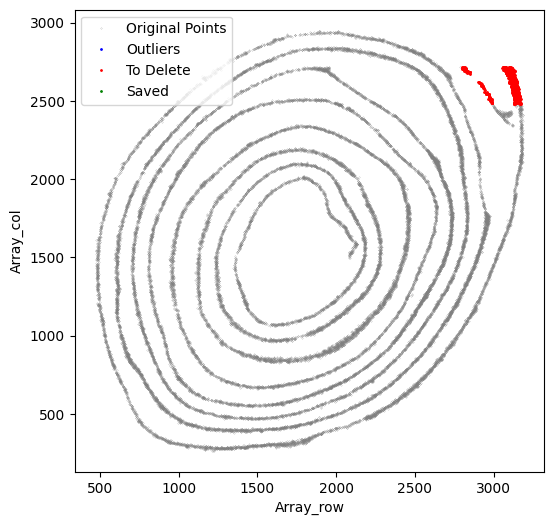

In [54]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     down = 2480, left = 2800,  
                                                     outlier_cutoff = 18, 
                                                     outlier_neighbors = 10, 
                                                     return_deleted = True,
                                                     delete_xaxis = to_delete, 
                                                     k_neighbors = 40, 
                                                     avg_iterations = 1)

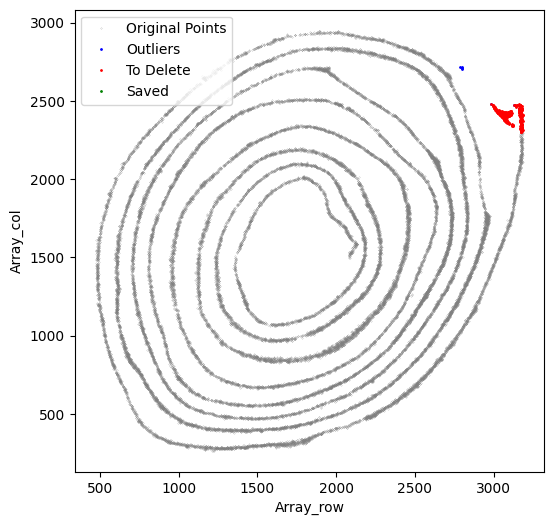

In [55]:
selected_smallintestine, to_delete = su.clean_select(selected_smallintestine, 
                                                     down = 2300, left = 2900,  
                                                     outlier_cutoff = 18, 
                                                     outlier_neighbors = 10, 
                                                     return_deleted = True,
                                                     delete_xaxis = to_delete, 
                                                     k_neighbors = 40, 
                                                     avg_iterations = 1)

Run `su.x_axis_pre` again to confirm that the x-axis fit is now satisfactory.

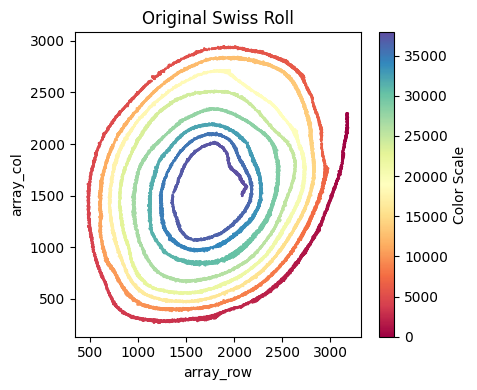

In [56]:
su.x_axis_pre(selected_smallintestine, seed = 42, n_neighbors = 20)

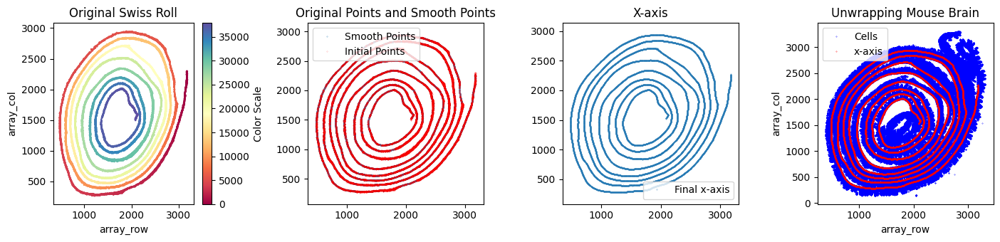

One unit length on the x-axis is 5.00 μm. The total x-axis length is 9.0165 cm.


In [57]:
x_axis_results_smallintestine = su.x_axis(selected_smallintestine, 
                                          adata = adata_sc_final_smallintestine, 
                                          seed = 42, n_neighbors = 20)

## Small intestine: selecting the remaining cells for y-axis analysis

Use `su.select_rest_cells()` to collect all cells that are not part of the fitted x-axis.

In [58]:
cells_smallintestine = su.select_rest_cells(
    adata_sc_final_smallintestine,
    selected = selected_smallintestine,
    delete_xaxis = to_delete
)

## Small intestine: generating final flattened coordinates with `su.y_axis_circle()`

Note that `center` and `outside` control the direction of y-axis expansion. Since many circular tissues have a natural center, we provide the option to specify it explicitly. If y should extend outward, set `outside=True`; if it should extend inward, set `outside=False`. If no such center is needed, you can omit this parameter.

116it [37:03, 19.17s/it, Layer=115]


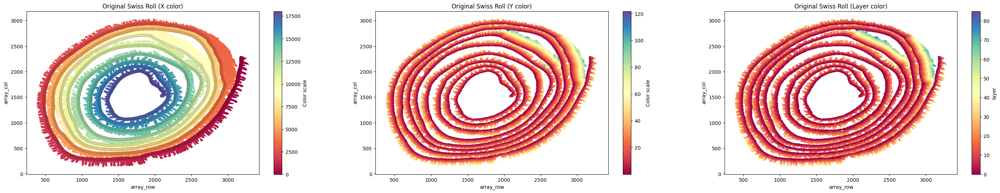

In [59]:
final_result_smallintestine = su.y_axis_circle(
    x_axis_results_smallintestine,
    cells_smallintestine,
    delete_xaxis = to_delete,
    selected = selected_smallintestine,
    n_neighbors_first = 18,
    n_neighbors_rest = 7,
    distance_cutoff = 23,
    center = np.array([1750, 1600]),
    outside = True
)